# Практическая работа №1
## Первичный анализ данных (EDA)

### Цель работы
Выполнить первичный анализ набора данных Titanic:
изучить структуру данных, типы признаков, пропуски,
статистические характеристики и построить визуализации.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


## 1. Загрузка данных

In [14]:
from pathlib import Path

# Определяем расположение файла
data_path = Path("data/titanic.csv")

if not data_path.exists():
    data_path = Path("../data/titanic.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "Не найден файл titanic.csv. "
        "Проверь, находится ли он в папке data."
    )

df = pd.read_csv(data_path)

print("Датасет успешно загружен!")
print("Путь к файлу:", data_path)

Датасет успешно загружен!
Путь к файлу: ..\data\titanic.csv


## 2. Размер датасета

In [15]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Размер таблицы:", df.shape)

Количество строк: 891
Количество столбцов: 12
Размер таблицы: (891, 12)


## 3. Первичный просмотр данных

In [16]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 4. Типы данных


In [17]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

## 5. Анализ пропущенных значений

In [18]:
missing_values = df.isnull().sum()

display(missing_values)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 6. Базовые статистические характеристики

In [19]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [20]:
df.describe(include="object")

C:\Users\user\AppData\Local\Temp\ipykernel_21324\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## 7. Визуализация данных

### 7.1. Распределение возраста пассажиров

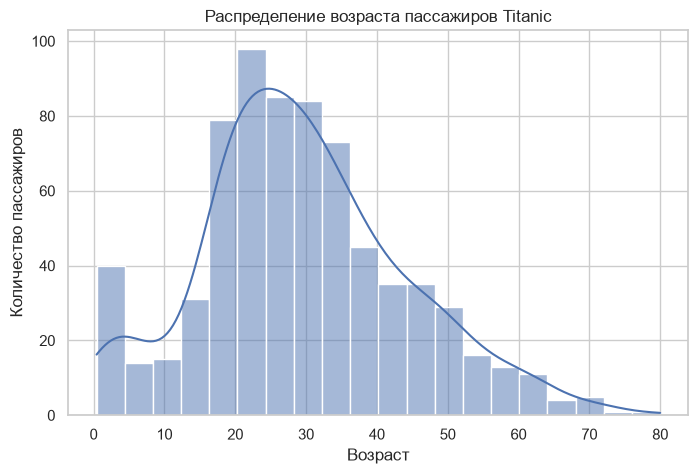

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Распределение возраста пассажиров Titanic")
plt.xlabel("Возраст")
plt.ylabel("Количество пассажиров")

plt.show()

### 7.2. Соотношение пассажиров по полу

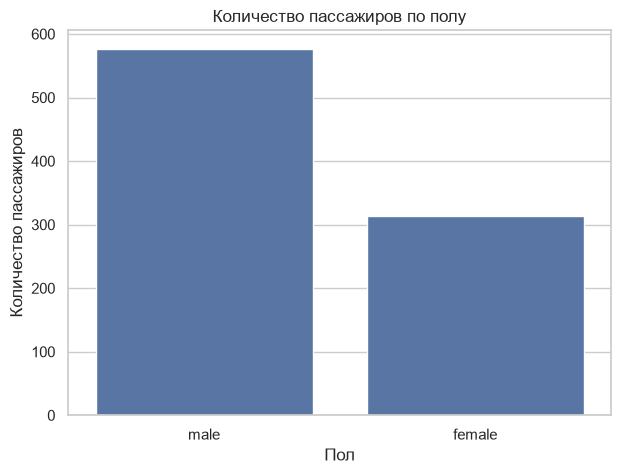

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex")

plt.title("Количество пассажиров по полу")
plt.xlabel("Пол")
plt.ylabel("Количество пассажиров")

plt.show()

### 7.3. Соотношение выживших и погибших пассажиров

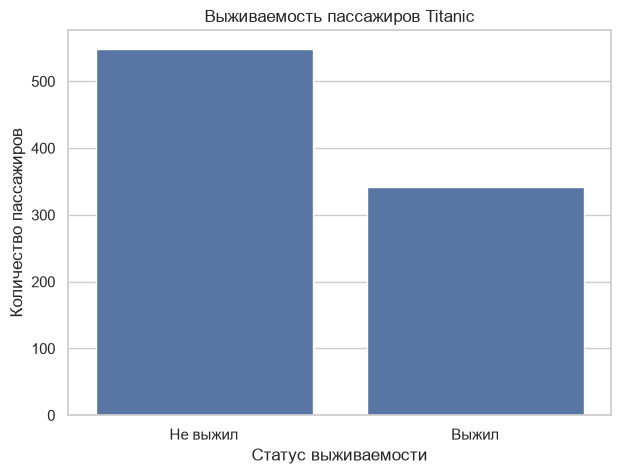

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Выживаемость пассажиров Titanic")
plt.xlabel("Статус выживаемости")
plt.ylabel("Количество пассажиров")

plt.xticks([0, 1], ["Не выжил", "Выжил"])

plt.show()

## 8. Наблюдения по результатам анализа

1. В датасете представлены пассажиры разных возрастных групп,
однако данные о возрасте имеются не для всех пассажиров.
Это необходимо учитывать при анализе возрастного распределения.

2. В наборе данных одновременно представлены числовые и категориальные
признаки. Это позволяет исследовать данные разными способами
и использовать различные методы визуализации.

3. Столбец Cabin содержит большое количество пропущенных значений,
что ограничивает возможность полноценного анализа пассажиров
по номерам кают.

## 9. Итог

В ходе практической работы был выполнен первичный анализ датасета Titanic.
Были изучены структура таблицы, типы данных, пропущенные значения
и базовые статистические характеристики.

Для визуального анализа построены графики распределения возраста
пассажиров, соотношения пассажиров по полу и выживаемости.

В результате были освоены основные этапы первичного анализа данных
с использованием библиотек Python.